In [43]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [44]:
df = pd.read_csv("smartcart_customers.csv")

In [45]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


# Data Preprocessing

# 1. Handle Missing Values

In [4]:
df["Income"] = df["Income"].fillna(df["Income"].median())

# Feature Engineering

In [5]:
# Age

df["Age"] = df["Year_Birth"].max() - df["Year_Birth"]

In [6]:
# Customer Joining Date

df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"] , dayfirst = True)
reference_date = df["Dt_Customer"].max()
df["Customer_Tenure_Days"] = (reference_date - df["Dt_Customer"]).dt.days

In [7]:
# Spending

df["Total_Spending"] = df["MntWines"] + df["MntFruits"] + df["MntMeatProducts"] + df["MntFishProducts"] + df["MntSweetProducts"] + df["MntGoldProds"]

In [8]:
# Children

df["Total_Children"] = df["Kidhome"] + df["Teenhome"]

In [9]:
# Education 

df["Education"].value_counts()

df["Education"] = df["Education"].replace({
    "Graduation" : "Graduate",
    "2n Cycle" : "Undergraduate" , "Basic" : "Undergraduate",
    "PhD" : "Postgraduate" , "Master" : "Postgraduate"
})

In [10]:
df["Education"].value_counts()

Education
Graduate         1127
Postgraduate      856
Undergraduate     257
Name: count, dtype: int64

In [11]:
# Marital Status

df["Marital_Status"].value_counts()

df["Living_With"] = df["Marital_Status"].replace({
    "Married" : "Partner", "Together" : "Partner",
    "Single" : "Alone" , "Divorced" : "Alone",
    "Widow" : "Alone" , "Absurd" : "Alone" , "YOLO" : "Alone"
})

In [12]:
df["Living_With"].value_counts()

Living_With
Partner    1444
Alone       796
Name: count, dtype: int64

# Drop Columns

In [13]:
cols_to_drop = ["ID" , "Year_Birth" , "Marital_Status" , "Kidhome" , "Teenhome" ,"Dt_Customer" , "MntWines" , "MntFruits" , "MntMeatProducts" , "MntFishProducts" , "MntSweetProducts" , "MntGoldProds"]

df_cleaned = df.drop(columns = cols_to_drop)

In [14]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_With
0,Graduate,58138.0,58,3,8,10,4,7,0,1,39,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,42,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,31,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,12,139,53,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,15,161,422,1,Partner


# Outliers

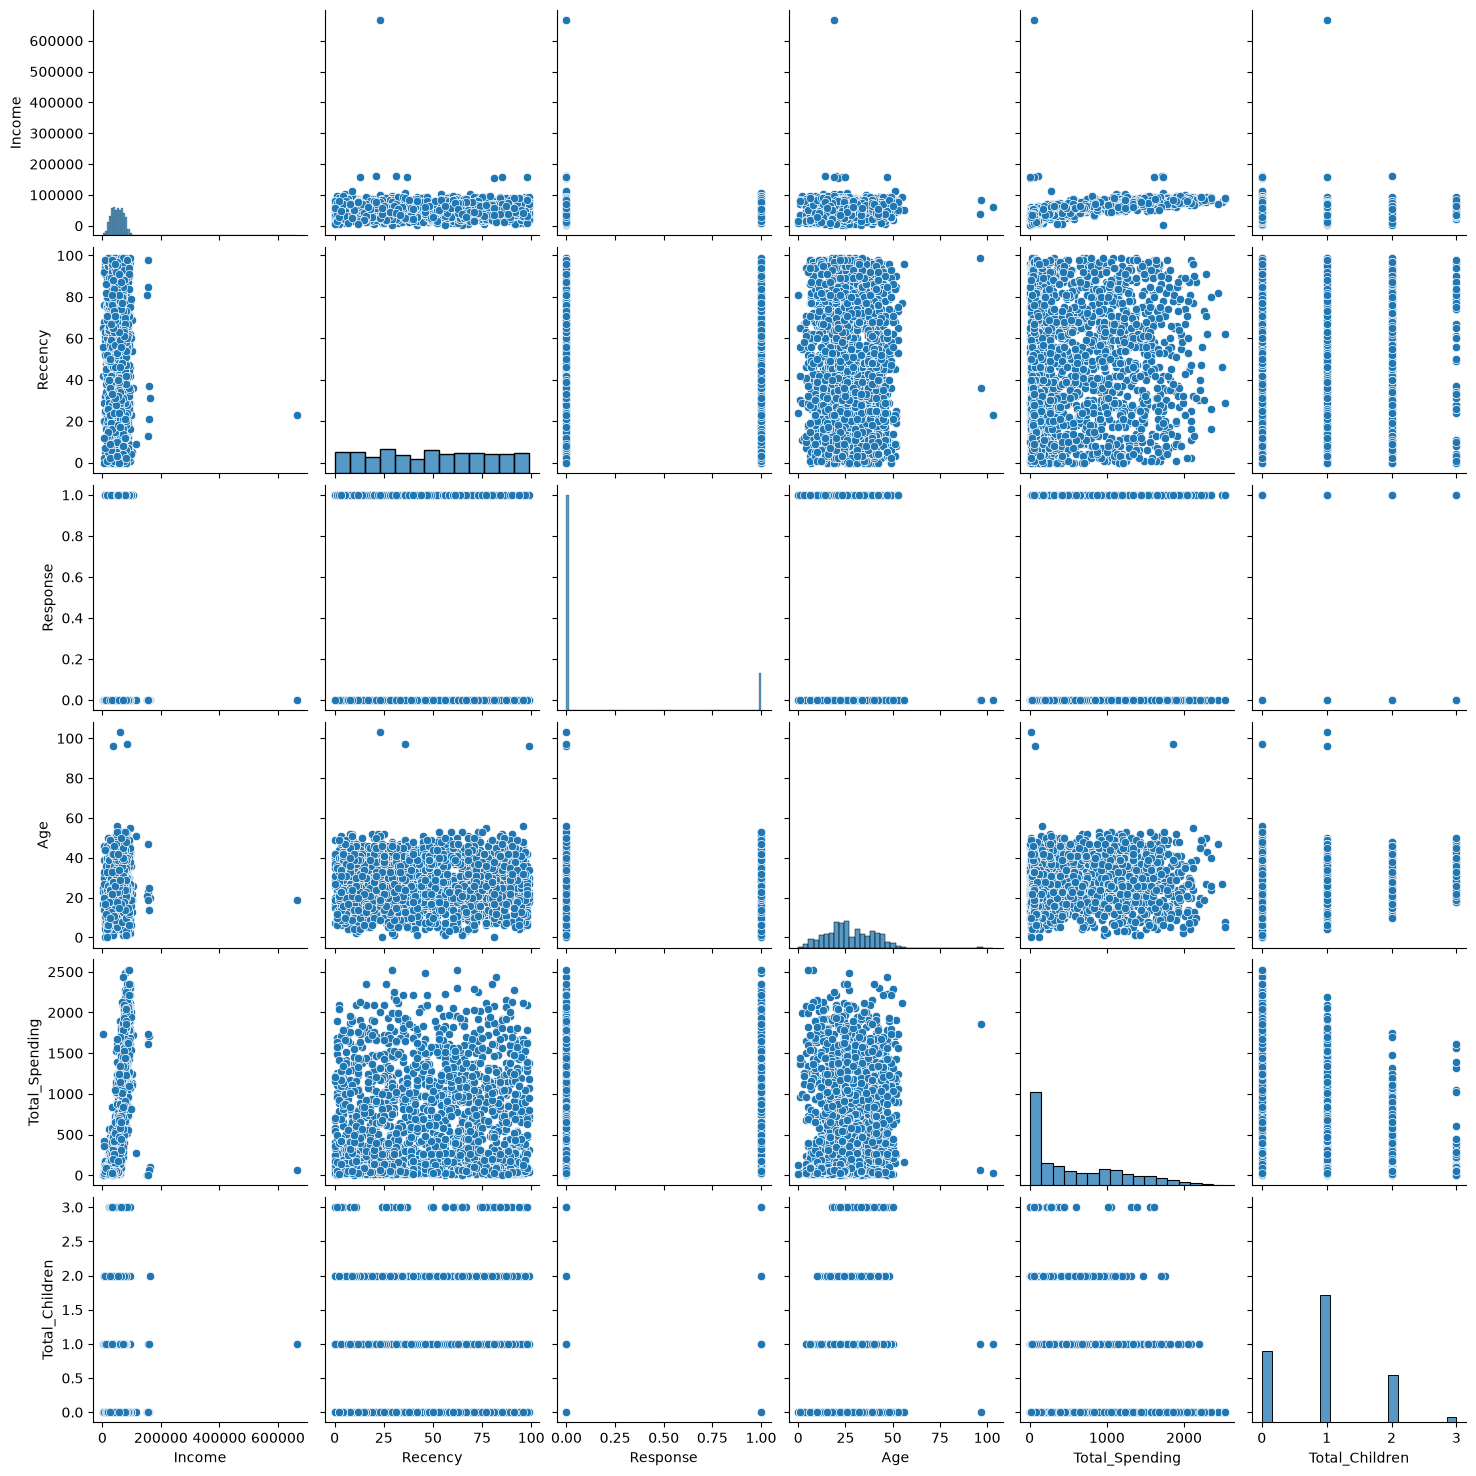

In [15]:
cols = ["Income" , "Recency" , "Response" , "Age" , "Total_Spending" , "Total_Children"]

# Relative Plots of Some Features - Pair Plot

sns.pairplot(df_cleaned[cols])

In [16]:
# Remove Outliers

print("Data size with Outliers : " , len(df_cleaned))

df_cleaned = df_cleaned[(df_cleaned["Age"] < 90 )]
df_cleaned = df_cleaned[(df_cleaned["Income"] < 600_000 )]

print("Data size without Outliers : " , len(df_cleaned))

Data size with Outliers :  2240
Data size without Outliers :  2236


# HeatMap

In [17]:
corr = df_cleaned.corr(numeric_only = True)

<Axes: >

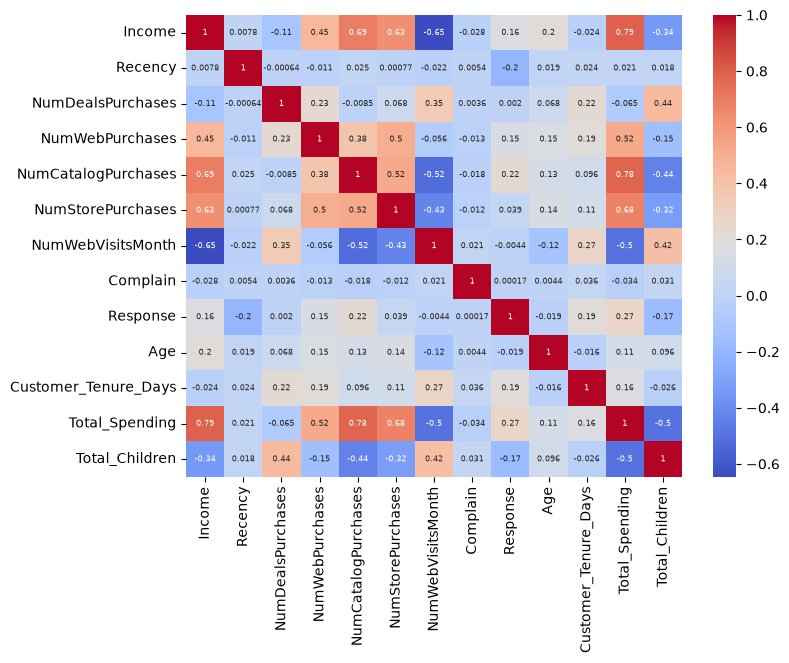

In [18]:
plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    annot_kws = {"size" : 6},
    cmap = "coolwarm"
) 

# Encoding

In [19]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_With
0,Graduate,58138.0,58,3,8,10,4,7,0,1,39,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,42,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,31,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,12,139,53,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,15,161,422,1,Partner


In [20]:
from sklearn.preprocessing import OneHotEncoder

In [21]:
ohe = OneHotEncoder()

cat_cols = ["Education" , "Living_With"]

enc_cols = ohe.fit_transform(df_cleaned[cat_cols])

In [22]:
enc_df = pd.DataFrame(enc_cols.toarray() , columns = ohe.get_feature_names_out(cat_cols) , index = df_cleaned.index)

In [23]:
enc_df.head()

,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner
0,1.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,1.0


In [24]:
df_encoded = pd.concat([df_cleaned.drop(columns = cat_cols) , enc_df] , axis = 1)

In [25]:
df_encoded.shape

(2236, 18)

In [26]:
df_encoded.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner
0,58138.0,58,3,8,10,4,7,0,1,39,663,1617,0,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,42,113,27,2,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,31,312,776,0,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,12,139,53,1,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,15,161,422,1,0.0,1.0,0.0,0.0,1.0


# Scaling

In [27]:
from sklearn.preprocessing import StandardScaler

In [28]:
X = df_encoded

In [29]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Visualize

In [30]:
from sklearn.decomposition import PCA

In [31]:
pca = PCA(n_components = 3)

X_pca = pca.fit_transform(X_scaled)

In [32]:
pca.explained_variance_ratio_

array([0.23163158, 0.11385454, 0.10405815])

Text(0.5, 0.92, '3D Projection')

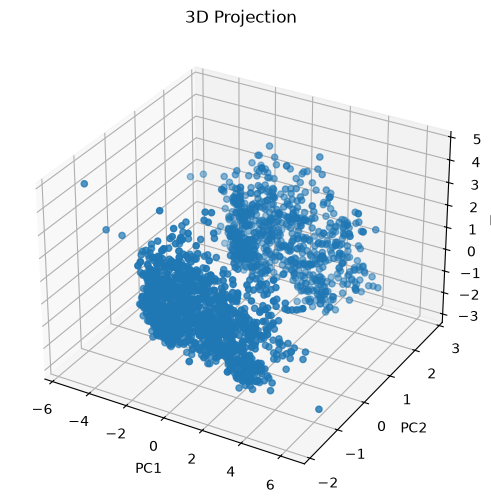

In [33]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111 , projection = "3d")
ax.scatter(X_pca[:,0] , X_pca[:,1] , X_pca[:,2])

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("3D Projection")

# Analyze Optimal K Value

# 1. Elbow Method

In [34]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

In [35]:
wcss = []
for k in range(1,11):
    kmeans = KMeans(n_clusters = k , random_state = 42)
    kmeans.fit_predict(X_pca)
    wcss.append(kmeans.inertia_)

In [36]:
knee = KneeLocator(range(1,11) , wcss , curve = "convex" , direction = "decreasing")
optimal_k = knee.elbow

In [37]:
print("Best K : " , optimal_k)

Best K :  4


Text(0, 0.5, 'WCSS')

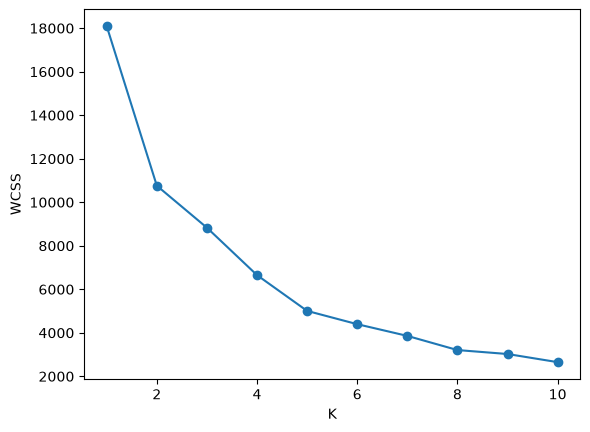

In [38]:
plt.plot(range(1,11) , wcss , marker = 'o')
plt.xlabel("K")
plt.ylabel("WCSS")

# 2. Silhouette Score

In [39]:
from sklearn.metrics import silhouette_score

In [40]:
scores = []

for k in range(2,11):
    kmeans  = KMeans(n_clusters = k , random_state = 42)
    labels = kmeans.fit_predict(X_pca)
    score = silhouette_score(X_pca , labels)
    scores.append(score)

Text(0, 0.5, 'Silhouette Score ')

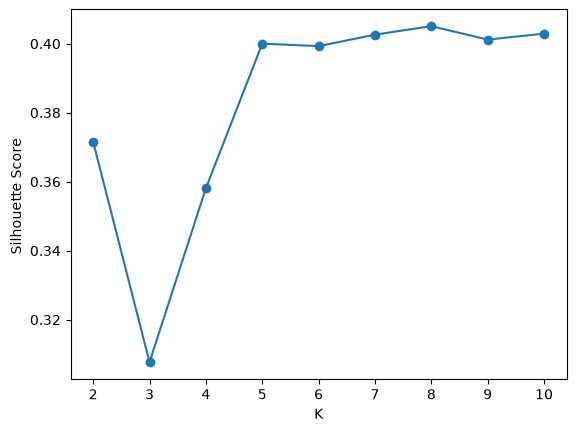

In [41]:
plt.plot(range(2,11) , scores , marker = 'o')
plt.xlabel("K")
plt.ylabel("Silhouette Score ")

Text(0, 0.5, 'Silhouette Score')

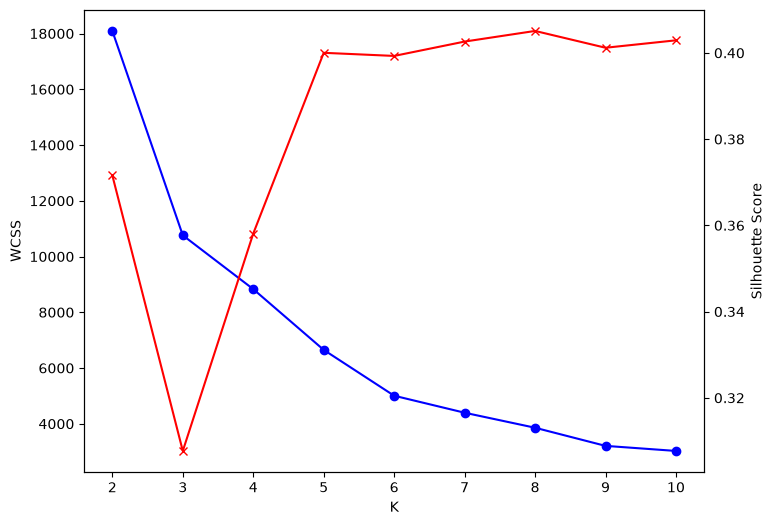

In [42]:
# Combined Plot

k_range = range(2,11)

fig , ax1 = plt.subplots(figsize = (8,6))

ax1.plot(k_range , wcss[:len(k_range)] , marker = 'o' , color = "blue")
ax1.set_xlabel("K")
ax1.set_ylabel("WCSS")

ax2 = ax1.twinx()
ax2.plot(k_range , scores[:len(k_range)] , marker = 'x' , color = "red")
ax2.set_ylabel("Silhouette Score")

# Clustering

In [46]:
# KMeans

kmeans = KMeans(n_clusters = 4 , random_state = 42)
labels_kmeans = kmeans.fit_predict(X_pca)

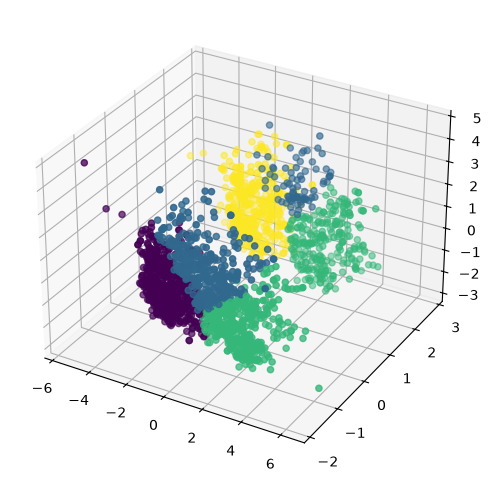

In [47]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111 , projection = "3d")
ax.scatter(X_pca[:,0] , X_pca[:,1] , X_pca[:,2] , c = labels_kmeans)

In [50]:
# Agglomerative Clustering
from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(n_clusters = 4 , linkage = "ward")
labels_agg = agg.fit_predict(X_pca)

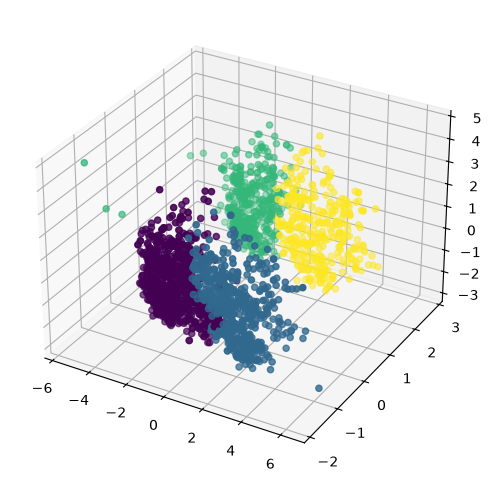

In [51]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111 , projection = "3d")
ax.scatter(X_pca[:,0] , X_pca[:,1] , X_pca[:,2] , c = labels_agg)

# Characterization of Clusters

In [60]:
X["Cluster"] = labels_agg

In [61]:
X.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner,Cluster
0,58138.0,58,3,8,10,4,7,0,1,39,663,1617,0,1.0,0.0,0.0,1.0,0.0,3
1,46344.0,38,2,1,1,2,5,0,0,42,113,27,2,1.0,0.0,0.0,1.0,0.0,2
2,71613.0,26,1,8,2,10,4,0,0,31,312,776,0,1.0,0.0,0.0,0.0,1.0,1
3,26646.0,26,2,2,0,4,6,0,0,12,139,53,1,1.0,0.0,0.0,0.0,1.0,0
4,58293.0,94,5,5,3,6,5,0,0,15,161,422,1,0.0,1.0,0.0,0.0,1.0,0


<Axes: xlabel='Cluster', ylabel='count'>

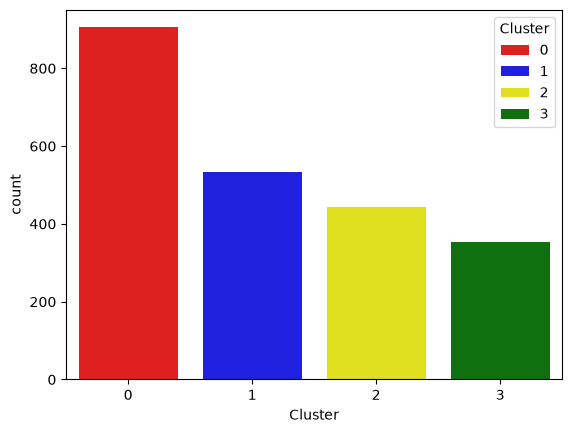

In [62]:
pal = ["red" , "blue" ,"yellow" , "green"]

sns.countplot(x=X["Cluster"] , palette = pal , hue = X["Cluster"])

<Axes: xlabel='Total_Spending', ylabel='Income'>

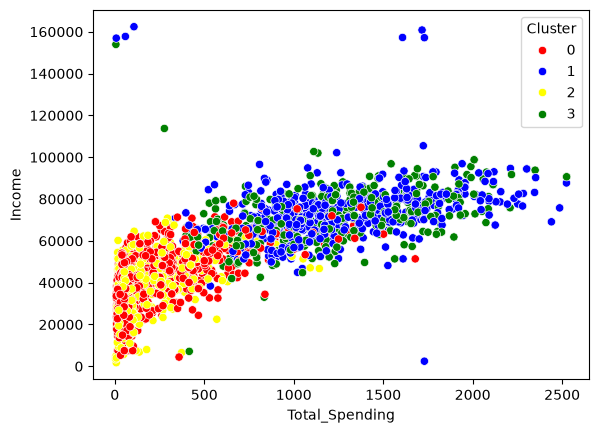

In [63]:
# Income and Total_Spending Patterns

sns.scatterplot(x=X["Total_Spending"] , y=X["Income"] , hue = X["Cluster"] , palette = pal)

# Cluster Summary

In [64]:
cluster_summary = X.groupby("Cluster").mean()
print(cluster_summary)

               Income    Recency  NumDealsPurchases  NumWebPurchases  \
Cluster                                                                
0        39680.580110  48.914917           2.594475         3.153591   
1        72808.445693  49.202247           1.958801         5.687266   
2        36960.143018  48.319820           2.594595         2.713964   
3        70722.681303  50.504249           1.855524         5.790368   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
Cluster                                                                        
0                   0.969061           4.143646           6.307182  0.011050   
1                   5.498127           8.659176           3.580524  0.005618   
2                   0.837838           3.623874           6.659910  0.011261   
3                   5.014164           8.430595           3.728045  0.005666   

         Response        Age  Customer_Tenure_Days  Total_Spending  \
Cluster         